<a href="https://colab.research.google.com/github/chaehyeonkim-lab/Introduction-to-Bioinformatics/blob/main/AIBio2026_Mission3_ChaehyeonKim.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mission 3
## Train a CNN for image classification (CIFAR-10)

Objective: improve the image classification accuracy of Mission 2 (MLP, 50-60%) to >85% by using a CNN and practical deep learning techniques.\
We will use GPU for this mission, so please select the T4 GPU runtime on Google Colab.

**Due date: Nov 15th (Sun) 23:59**

Mission requirements:
* Build a CNN model with at least 6 convolutional layers (tip: about 1 million parameters are enough).
* Use Adam, batch normalization, dropout, L2 regularization (weight decay), and LR scheduling.
* **Achieve an overall test accuracy of >85%.**

Files to submit:
* Jupyter notebook (AIBio2026_Mission3_GildongHong.ipynb)
* Test set prediction result (AIBio2026_Mission3_GildongHong.tsv)
* Change the name of the file with your name.

How to submit:
* Submit your files via email to baek@snu.ac.kr
* Please use the following header: [생물정보학] Mission3

Rules:
* Use the provided notebook template (AIBio2026_Mission3_forstudents.ipynb)
* Only the training dataset given in the template notebook can be used. Do not augment the data.
* Do not add or change random seeds anywhere in the notebook.
* Do not modify the train/test set split. You should split the validation set from the train set.
* Before submitting, run all cells from top to bottom in a fresh session (Runtime → Restart session and run all), so that the notebook and the TSV file come from a single run.


### Enter your name below

In [1]:
student_name = "ChaehyeonKim"  ### Replace with your name, no space ###

### Imports and settings
**DO NOT MODIFY the code below.**\
Do not add or change random seeds (e.g., `torch.manual_seed`) anywhere in the notebook. The seeds in the provided code make your results reproducible.

In [2]:
%matplotlib inline

import copy

import numpy as np
import torch
from torch import nn, optim

import tqdm
import torchvision

from matplotlib import pyplot as plt
import seaborn as sns
import pandas as pd

# Set plotting style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'font.size': 13})

# Set global random seed
np.random.seed(42)
torch.manual_seed(42)
# Make GPU results reproducible (cuDNN may otherwise choose different algorithms between runs)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

### Load CIFAR10 dataset
**DO NOT MODIFY the code below (only modify the `root` path if needed).**\
We will use the CIFAR-10 dataset, which consists of 60,000 32x32 color images in 10 classes, with 6,000 images per class. There are 50,000 training images and 10,000 test images. The original download server (cs.toronto.edu) has become very slow, so we download the same images from the Hugging Face mirror.

In [3]:
import io, os, urllib.request
from PIL import Image

def load_cifar10(root='./data'):
    # The original CIFAR-10 server (cs.toronto.edu) has become very slow, so we download the same
    # images from the Hugging Face mirror: https://huggingface.co/datasets/uoft-cs/cifar10
    url = 'https://huggingface.co/datasets/uoft-cs/cifar10/resolve/main/plain_text/{}-00000-of-00001.parquet'
    os.makedirs(root, exist_ok=True)

    def load_split(split):
        path = os.path.join(root, f'cifar10_{split}.parquet')
        if not os.path.exists(path):
            urllib.request.urlretrieve(url.format(split), path + '.part')
            os.replace(path + '.part', path)
        df = pd.read_parquet(path)
        images = np.stack([np.array(Image.open(io.BytesIO(img['bytes'])).convert('RGB')) for img in df['img']])
        images = torch.from_numpy(images).permute(0, 3, 1, 2).float() / 255  # same as ToTensor()
        images = (images - 0.5) / 0.5  # same as Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
        labels = torch.tensor(df['label'].to_numpy())
        return torch.utils.data.TensorDataset(images, labels)

    train_val_set = load_split('train')
    test_set = load_split('test')
    classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')
    return train_val_set, test_set, classes

train_val_set, test_set, classes = load_cifar10()

### Split dataset into training and validation sets
**DO NOT MODIFY the code below.**\
We use 90% of the training data for training and 10% for validation. The fixed-seed generator makes the split identical on every run.

In [4]:
def split_train_val(train_val_set):
    # Define set sizes (90% train, 10% validation)
    train_size = int(0.9 * len(train_val_set))
    val_size = len(train_val_set) - train_size

    # Split the dataset (the fixed-seed generator makes the split identical on every run)
    generator = torch.Generator().manual_seed(42)
    train_set, val_set = torch.utils.data.random_split(train_val_set, [train_size, val_size], generator=generator)

    print(f"[Sample count] Train: {len(train_set)} / Val: {len(val_set)} / Test: {len(test_set)}")
    return train_set, val_set

train_set, val_set = split_train_val(train_val_set)

[Sample count] Train: 45000 / Val: 5000 / Test: 10000


### Create DataLoaders
**DO NOT MODIFY the code below (you may change the batch size).**\
Only the training set is shuffled.

In [5]:
# Create data loaders for the new sets
batch_size = 128 # You may change this value

train_loader = torch.utils.data.DataLoader(train_set, batch_size=batch_size, shuffle=True)
val_loader = torch.utils.data.DataLoader(val_set, batch_size=batch_size, shuffle=False)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=batch_size, shuffle=False)

print(f"[Batch count] Train: {len(train_loader)} / Val: {len(val_loader)} / Test: {len(test_loader)}")

[Batch count] Train: 352 / Val: 40 / Test: 79


### Show example data
**DO NOT MODIFY the code below.**

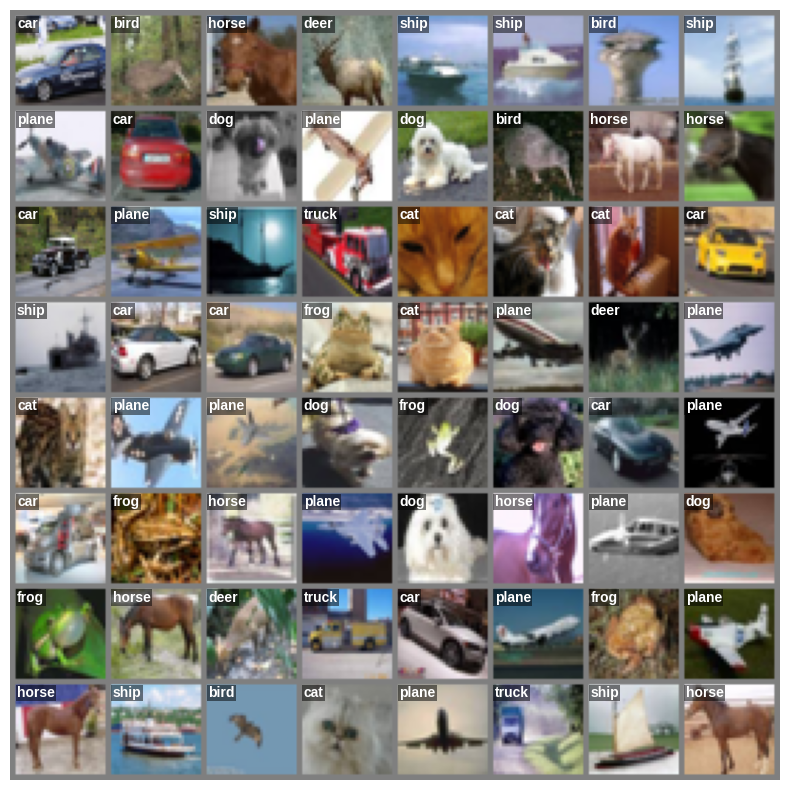

In [6]:
# function to unnormalize an image
def unnormalize(img):
    img = img / 2 + 0.5
    img = img.numpy()
    img = np.transpose(img, (1, 2, 0))
    return img

# Show 64 images from the training set
def show_example_data(train_set, classes):
    grid = torchvision.utils.make_grid([train_set[i][0] for i in range(64)], nrow=8)
    labels = [classes[train_set[i][1]] for i in range(64)]
    plt.figure(figsize=(10, 10))
    plt.imshow(unnormalize(grid))
    for i, label in enumerate(labels):
        plt.text((i % 8) * (32 + 2) + 2, (i // 8) * (32 + 2) + 6, label, color='white', fontsize=10, weight='bold',
                 bbox=dict(facecolor='black', alpha=0.5, edgecolor='none', pad=1))
    plt.axis('off')
    plt.show()

show_example_data(train_set, classes)

### Build a Convolutional Neural Network

**Mission**: Define a `ConvBlock` with a 2-D convolution layer, a batch normalization layer, a ReLU layer, and a dropout layer, applied in this order. The input channels (`c_in`), output channels (`c_out`), kernel size (`k`), padding (`p`), whether to use batch normalization (`use_batchnorm`), and the dropout rate (`p_drop`) should be configurable.

In [7]:
class ConvBlock(nn.Module):
    def __init__(self, c_in, c_out, k=3, p=1, use_batchnorm=True, p_drop=0.0):
        super().__init__()
        #### YOUR CODE HERE #### - Define the layers. Use nn.Identity() for a layer that is turned off.
        self.conv = nn.Conv2d(c_in, c_out, k , padding = p)
        self.bn = nn.BatchNorm2d(c_out) if use_batchnorm else nn.Identity()
        self.act = nn.ReLU()
        self.dropout = nn.Dropout(p_drop) if p_drop > 0 else nn.Identity()

    def forward(self, x):
        #### YOUR CODE HERE #### - Apply the layers in order.
        x = self.conv(x)
        x = self.bn(x)
        x = self.act(x)
        x = self.dropout(x)
        return x

**Mission**: Define a convolutional neural network with at least 6 ConvBlock layers. Use max pooling and average pooling layers, batch normalization, and dropout. Send the model to GPU.

In [10]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        #### YOUR CODE HERE #### - Define the layers using ConvBlock, pooling layers, and fully connected layers.
        self.features = nn.Sequential(
            ConvBlock(3, 64, use_batchnorm = True, p_drop = 0.3),
            nn.MaxPool2d(2),

            ConvBlock(64, 64, use_batchnorm = True, p_drop = 0.3),
            ConvBlock(64, 64, use_batchnorm = True, p_drop = 0.3),
            nn.MaxPool2d(2),

            ConvBlock(64, 256, use_batchnorm = True, p_drop = 0.3),
            ConvBlock(256, 256, use_batchnorm = True, p_drop = 0.3),
            ConvBlock(256, 256, use_batchnorm = True, p_drop = 0.3),

            nn.AdaptiveAvgPool2d(1),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 10),
        )

    def forward(self, x):
        #### YOUR CODE HERE ####
        x = self.features(x)
        x = self.classifier(x)
        return x

## DO NOT MODIFY the line below. Re-seeding gives the same initial weights on every run. ##
torch.manual_seed(42)
model = CNN().cuda() #### YOUR CODE HERE #### - Create your CNN and send it to GPU.

**DO NOT MODIFY the code below.**\
Print the total number of parameters in the model. `model.parameters()` returns an iterator that yields each parameter tensor. `p.numel()` returns the number of elements in the tensor `p`.

In [11]:
total_params = sum(p.numel() for p in model.parameters())
print(f"Total number of parameters: {total_params:,}")

Total number of parameters: 1,542,154


### Implement a training loop
**Mission**: Implement a training loop to train the model. Use cross-entropy loss (`nn.CrossEntropyLoss`), the Adam optimizer (`optim.Adam`) with weight decay (`weight_decay=l2`), and a learning rate scheduler from `optim.lr_scheduler`. Move each batch of inputs and labels to the GPU with `.cuda()`. You may choose the learning rate (`lr`), weight decay (`l2`), and the number of epochs (`epochs`).\
If you change these values, re-run the cells from the model definition onward. Otherwise, training continues from the already-trained model.

In [16]:
def train_model(model, train_loader, val_loader, lr, l2, epochs):

    criterion = nn.CrossEntropyLoss() #### YOUR CODE HERE ####
    optimizer = optim.Adam(model.parameters(), lr = lr, weight_decay = l2) #### YOUR CODE HERE ####
    scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones = [15])

    t_loss_history = []
    v_loss_history = []
    best_model_state = None

    for epoch in tqdm.tqdm(range(epochs)):  # loop over the dataset multiple times

        model.train()  # training mode (matters for Dropout and BatchNorm)
        #### YOUR CODE HERE #### - Implement the forward and backward passes. Append t_loss to t_loss_history.
        t_loss = 0.0

        for inputs, labels in train_loader:
            inputs, labels = inputs.cuda(), labels.cuda()

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            t_loss += loss.item() * len(labels)
        t_loss /= len(train_loader.dataset)
        t_loss_history.append(t_loss)

        model.eval()  # evaluation mode
        #### YOUR CODE HERE #### - Implement the validation loss calculation and store it in v_loss.
        v_loss = 0.0

        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.cuda(), labels.cuda()
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                v_loss += loss.item() * len(labels)
        v_loss /= len(val_loader.dataset)

        #### YOUR CODE HERE #### - Update the learning rate with the scheduler.
        scheduler.step()

        # DO NOT MODIFY the lines below. This part selects the model with the lowest validation loss for evaluation.
        # deepcopy: state_dict() returns references to the live weights, which keep changing during training
        if epoch == 0 or v_loss < min(v_loss_history):
            best_model_state = copy.deepcopy(model.state_dict())
        v_loss_history.append(v_loss)

    print('Finished Training')
    model.load_state_dict(best_model_state)
    model.eval()

    return t_loss_history, v_loss_history

In [17]:
lr = 1e-3
l2 = 3e-4
epochs = 25

t_loss_history, v_loss_history = train_model(model, train_loader, val_loader, lr, l2, epochs) ## DO NOT MODIFY this line ##

100%|██████████| 25/25 [03:05<00:00,  7.41s/it]

Finished Training


### Plot training curve
**DO NOT MODIFY the code below.**

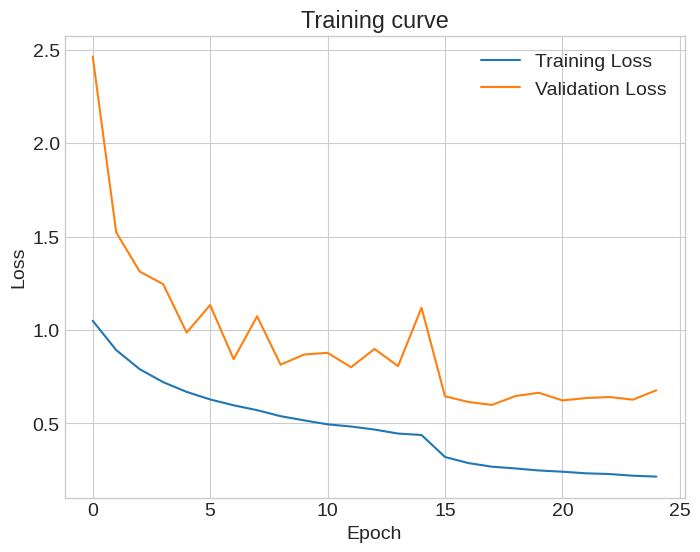

In [18]:
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'font.size': 14})

plt.figure(figsize=(8, 6))
plt.plot(t_loss_history, label='Training Loss')
plt.plot(v_loss_history, label='Validation Loss')
plt.title('Training curve')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

### Show examples from the test set data and their predictions
**DO NOT MODIFY the code below.**\
For intuition, we visualize 64 test images along with their true and predicted labels. The predicted labels are colored green if correct and red if incorrect.

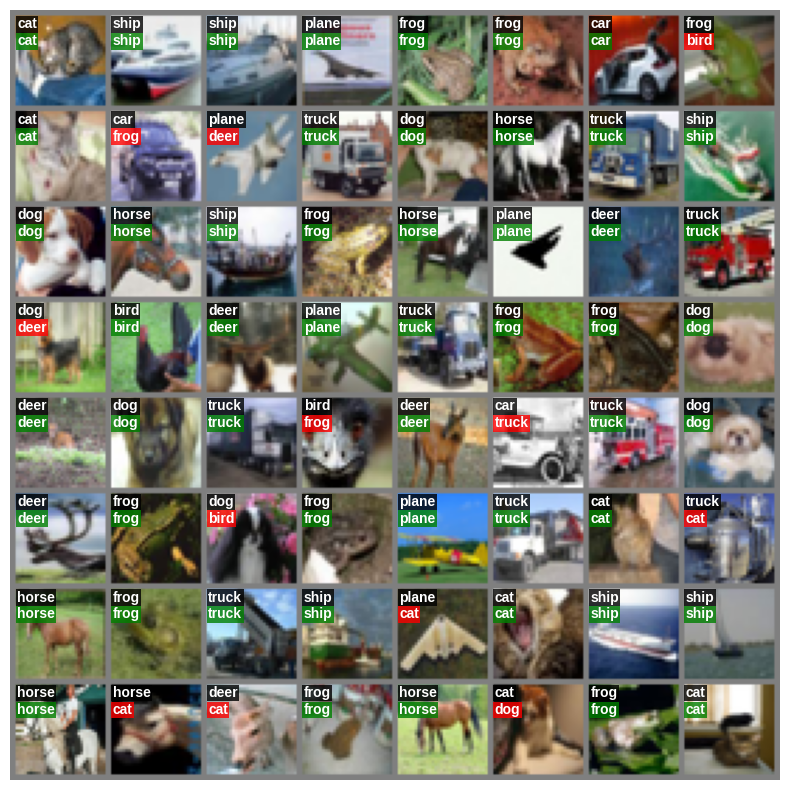

In [19]:
def plot_test_samples(test_set, classes, model):
    model.eval()
    images = torch.stack([test_set[i][0] for i in range(64)])
    grid = torchvision.utils.make_grid(images, nrow=8)
    labels = [classes[test_set[i][1]] for i in range(64)]
    with torch.no_grad():
        preds = [classes[p] for p in model(images.cuda()).argmax(dim=1).cpu()]
    plt.figure(figsize=(10, 10))
    plt.imshow(unnormalize(grid))
    for i, label in enumerate(labels):
        color = 'green' if label == preds[i] else 'red'
        plt.text((i % 8) * (32 + 2) + 2, (i // 8) * (32 + 2) + 6, label, color='white', fontsize=10, weight='bold',
                 bbox=dict(facecolor='black', alpha=0.8, edgecolor='none', pad=1))
        plt.text((i % 8) * (32 + 2) + 2, (i // 8) * (32 + 2) + 12, preds[i], color='white', fontsize=10, weight='bold',
                 bbox=dict(facecolor=color, alpha=0.8, edgecolor='none', pad=1))
    plt.axis('off')
    plt.show()
    return None

plot_test_samples(test_set, classes, model)

### Run evaluation on the test set
**DO NOT MODIFY the code below.**

In [20]:
def run_evaluation(model, test_loader):
    model.eval()
    labels_all = []
    preds_all = []
    with torch.no_grad():
        for inputs, labels in test_loader:
            outputs = model(inputs.cuda()).cpu()
            predicted = torch.argmax(outputs, dim=1)
            labels_all.append(labels.numpy())
            preds_all.append(predicted.numpy())
    labels_all = np.concatenate(labels_all)
    preds_all = np.concatenate(preds_all)
    return labels_all, preds_all

labels, preds = run_evaluation(model, test_loader)

print("labels:", labels.shape, labels.dtype) # labels: (10000,) int64
print("preds :", preds.shape, preds.dtype) # preds : (10000,) int64

labels: (10000,) int64
preds : (10000,) int64


### Visualize the confusion matrix
**DO NOT MODIFY the code below.**

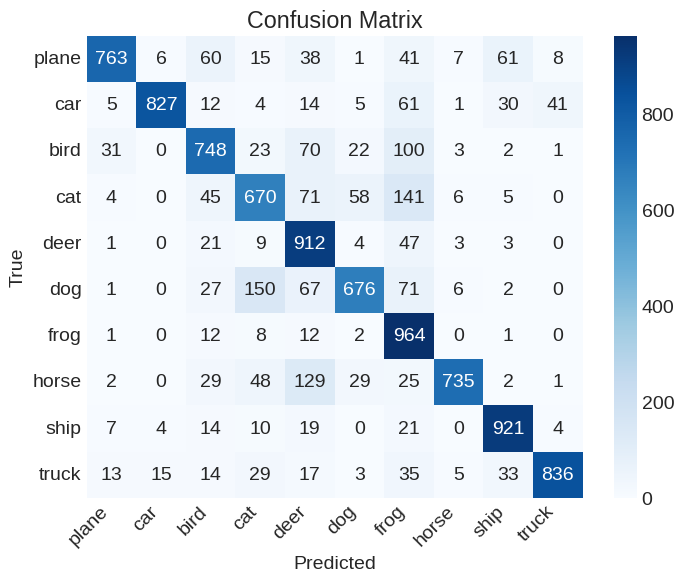

In [21]:
def make_confusion_matrix(labels, preds, n_classes):
    confusion_matrix = np.zeros((n_classes, n_classes), dtype=int)
    for true, pred in zip(labels, preds):
        confusion_matrix[true, pred] += 1
    return confusion_matrix

def plot_confusion_matrix(confusion_matrix, classes):
    plt.figure(figsize=(8, 6))
    sns.heatmap(confusion_matrix, annot=True, fmt='d', cmap = "Blues"
                , xticklabels=classes, yticklabels=classes)
    plt.xlabel('Predicted')
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.ylabel('True')
    plt.title('Confusion Matrix')
    plt.show()
    return None

confusion_matrix = make_confusion_matrix(labels, preds, len(classes))
plot_confusion_matrix(confusion_matrix, classes)

### Plot overall and per-class accuracy
**Check that the overall accuracy is >85%.**\
**DO NOT MODIFY the code below.**

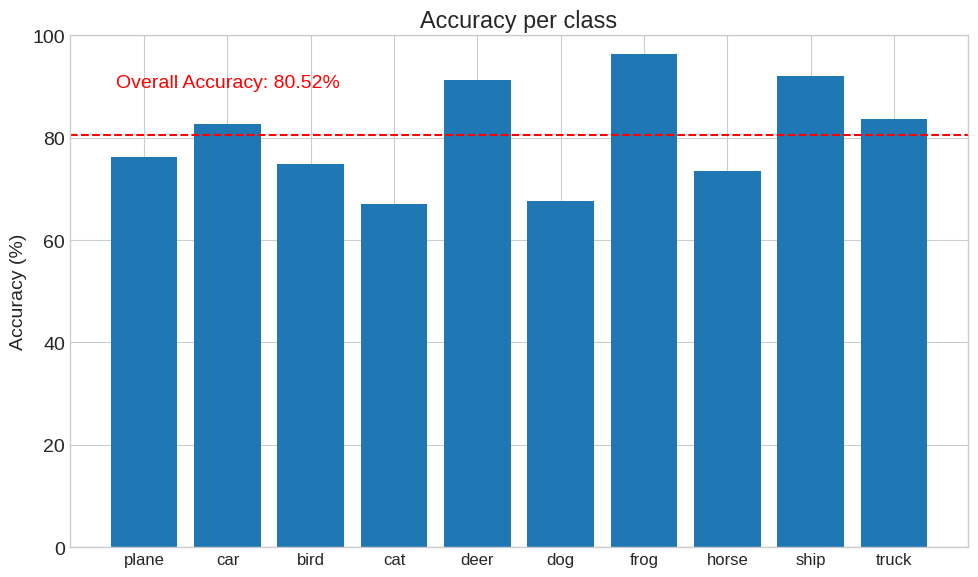

In [22]:
def calculate_and_plot_accuracy(confusion_matrix):

    # Data for plotting
    class_correct = confusion_matrix.diagonal()
    class_total = confusion_matrix.sum(axis=1)
    accuracy = 100 * class_correct / class_total
    overall_accuracy = 100 * class_correct.sum() / class_total.sum()

    # Plotting
    fig, ax = plt.subplots(figsize=(10, 6))
    y_pos = np.arange(confusion_matrix.shape[0])
    ax.bar(y_pos, accuracy, align='center')
    ax.axhline(y=overall_accuracy, color='r', linestyle='--', label='Overall Accuracy')
    ax.text(1, 90, f'Overall Accuracy: {overall_accuracy:.2f}%', color='red', ha='center')
    ax.set_ylim([0, 100])
    plt.xticks(y_pos, classes, fontsize=12)
    plt.ylabel('Accuracy (%)')
    plt.title('Accuracy per class')
    plt.tight_layout()
    plt.show()
    return None

calculate_and_plot_accuracy(confusion_matrix)

### Save output to TSV files (for submission)
**DO NOT MODIFY the code below (only modify the saving path if needed).**\
Make sure that you have run all the cells above before running the cell below. Double-check that your name is correctly set in the `student_name` variable at the top of the notebook. Submit the generated TSV file along with this notebook file.

In [ ]:
def save_predictions(labels, preds):
    df = {'True': labels,
          'Pred': preds}
    df = pd.DataFrame(df)
    df.to_csv(f'./data/AIBio2026_Mission3_{student_name}.tsv', sep='\t', index=False)
    return df

save_predictions(labels, preds)